## Mixture-of-products experiment

This notebook produces four figures:

1. dependence densities $\rho_N$ for several sequence lengths;
2. linear and factorization-error-optimal schedules at fixed $N=128$;
3. theoretical factorization errors and Monte Carlo boxplots for $N=2^3,\ldots,2^8$ with $K=\log_2 N$;
4. the ratio $\varepsilon_{\rm fact}^{\rm lin}/\varepsilon_{\rm fact}^{\rm opt}$.

The targets for different $N$ are nested prefixes of one mixture drawn at $N=256$. The next cell controls how finite-sample violations of information-profile monotonicity are handled.

In [1]:
# ## Choose how to handle monotonicity

# - Use "project" to replace a noisy nonmonotone estimate by its closest nondecreasing isotonic projection.
# - Use "raise" to stop and request more Monte Carlo samples.


PROFILE_MONOTONICITY = "project"  # allowed values: "project", "raise"


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

from optimal_schedules import (
    generate_mixture_parameters_dir,
    information_profile_mc,
    dependence_density,
    factorization_error,
    linear_schedule,
    optimal_schedule,
    kl_mc,
)

if not hasattr(np, "trapezoid"):
    np.trapezoid = np.trapz

plt.rcParams.update({
    "font.size": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 120,
    "lines.linewidth": 2,
})

C_LIN = "#7f8c8d"
C_OPT = "#2c6fbb"


# Target parameters from the paper
R, L, ALPHA = 5, 10, 0.3
SEED = 7

# Dimensions and schedules
NS = np.array([2**j for j in range(3, 9)])  # 8, ..., 256
NS_RHO = NS
N_SCHEDULE = 128
K_SCHEDULE = int(np.log2(N_SCHEDULE))

# Monte Carlo settings: increase these for the final paper figures
# N_PROFILE = 40_000
# N_KL = 4_000
# N_KL_REPS = 100
# N_GRID = 2_000
N_PROFILE = 4000
N_KL = 400
N_KL_REPS = 10
N_GRID = 2_000

In [3]:
from scipy.optimize import isotonic_regression

def information_profile_mc_batched(
    w, mu, n_samples, batch_size=4000,
    rng=None, monotonicity="project",
):
    if n_samples < 1 or batch_size < 1:
        raise ValueError("n_samples and batch_size must be positive")
    if monotonicity not in {"raise", "project"}:
        raise ValueError("monotonicity must be 'raise' or 'project'")
    if rng is None:
        rng = np.random.default_rng()

    total = np.zeros(mu.shape[1])

    for start in range(0, n_samples, batch_size):
        n = min(batch_size, n_samples - start)

        # Raw batch average: no projection within individual batches.
        f_batch = information_profile_mc(
            w, mu, n,
            rng=rng,
            monotonicity="none",
        )

        # Weight by batch size, including a shorter final batch.
        total += n * f_batch
        print(f"Profile draws: {start + n}/{n_samples}")

    f = total / n_samples

    # Enforce monotonicity only after pooling all draws.
    if np.any(np.diff(f) < 0):
        if monotonicity == "raise":
            raise RuntimeError(
                "The pooled profile is nonmonotone; "
                "increase n_samples or use 'project'."
            )
        f = isotonic_regression(f, increasing=True).x

    return f

In [ ]:
# Draw one target at the largest N and use nested prefixes for smaller N.
w, mu_max = generate_mixture_parameters_dir(
    R, int(NS.max()), L, ALPHA,
    rng=np.random.default_rng(SEED),
)

targets = {N: mu_max[:, :N, :].copy() for N in NS}
profiles = {}

for N in NS:
    # print(f"\nN = {N}")

    profiles[N] = information_profile_mc_batched(
        w,
        targets[N],
        N_PROFILE,
        batch_size=4_000,
        rng=np.random.default_rng(SEED + 1_000 + N),
        monotonicity=PROFILE_MONOTONICITY,
    )

### Figure 1: dependence density for varying $N$

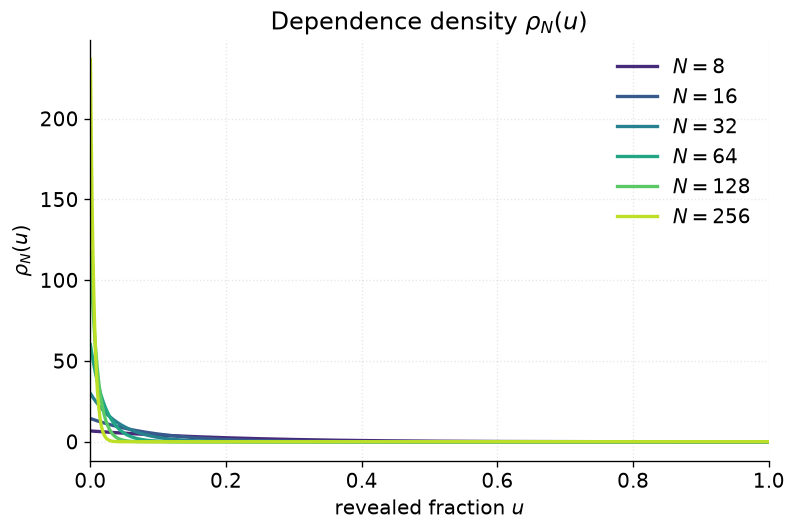

In [5]:
u = np.linspace(1e-4, 1 - 1e-4, 800)
colors = plt.cm.viridis(np.linspace(0.12, 0.90, len(NS_RHO)))

fig, ax = plt.subplots(figsize=(6.8, 4.6))

for N, color in zip(NS_RHO, colors):
    ax.plot(
        u,
        dependence_density(profiles[N], u),
        color=color,
        label=rf"$N={N}$",
    )

ax.set_title(r"Dependence density $\rho_N(u)$")
ax.set_xlabel(r"revealed fraction $u$")
ax.set_ylabel(r"$\rho_N(u)$")
ax.set_xlim(0, 1)
ax.legend(frameon=False)
ax.grid(True, ls=":", alpha=0.3)

fig.tight_layout()
# fig.savefig("figure1_rho.png", bbox_inches="tight", dpi=180)
# fig.savefig("figure1_rho.pdf", bbox_inches="tight")
plt.show()


### Figure 2: linear and optimal schedules at $N=128$

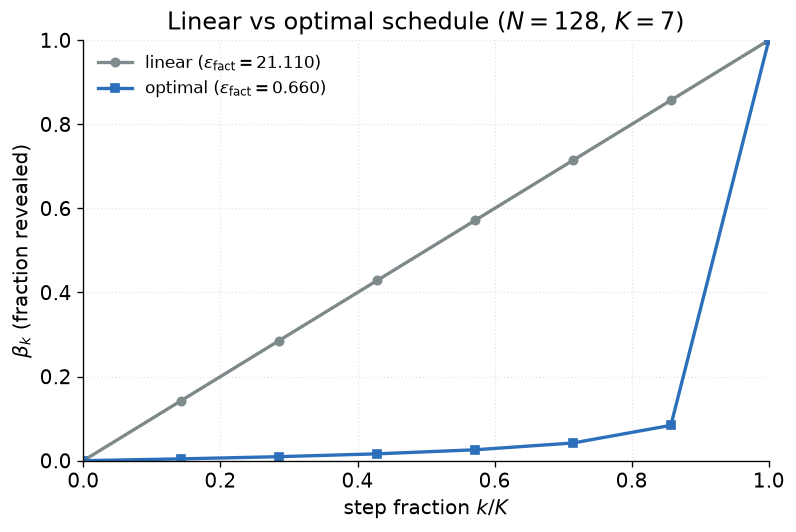

In [6]:
f_schedule = profiles[N_SCHEDULE]
beta_lin_fixed = linear_schedule(K_SCHEDULE)
beta_opt_fixed = optimal_schedule(
    f_schedule, K_SCHEDULE, n_grid=N_GRID
)

eps_lin_fixed = factorization_error(
    f_schedule, beta_lin_fixed, n_grid=N_GRID
)
eps_opt_fixed = factorization_error(
    f_schedule, beta_opt_fixed, n_grid=N_GRID
)

t = np.arange(K_SCHEDULE + 1) / K_SCHEDULE

fig, ax = plt.subplots(figsize=(6.8, 4.6))

ax.plot(
    t, beta_lin_fixed,
    color=C_LIN, marker="o", ms=5,
    label=rf"linear ($\varepsilon_{{\rm fact}}={eps_lin_fixed:.3f}$)",
)
ax.plot(
    t, beta_opt_fixed,
    color=C_OPT, marker="s", ms=5,
    label=rf"optimal ($\varepsilon_{{\rm fact}}={eps_opt_fixed:.3f}$)",
)
ax.plot([0, 1], [0, 1], ":", color="grey", lw=1)

ax.set_title(
    rf"Linear vs optimal schedule ($N={N_SCHEDULE}$, $K={K_SCHEDULE}$)"
)
ax.set_xlabel(r"step fraction $k/K$")
ax.set_ylabel(r"$\beta_k$ (fraction revealed)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend(frameon=False, fontsize=10, loc="upper left")
ax.grid(True, ls=":", alpha=0.3)

fig.tight_layout()
# fig.savefig("figure2_schedules_N128.png", bbox_inches="tight", dpi=180)
# fig.savefig("figure2_schedules_N128.pdf", bbox_inches="tight")
plt.show()


### Compute theoretical and repeated Monte Carlo errors

For every $N=2^3,\ldots,2^8$, the number of steps is $K=\log_2N$. Each boxplot contains N_KL_REPS independent estimates, each based on N_KL Monte Carlo samples.

In [7]:
eps_lin_theory = []
eps_opt_theory = []
eps_lin_mc = []
eps_opt_mc = []
KS = []

for n_index, N in enumerate(NS):
    K = int(np.log2(N))
    KS.append(K)

    f = profiles[N]
    mu = targets[N]
    beta_lin = linear_schedule(K)
    beta_opt = optimal_schedule(f, K, n_grid=N_GRID, return_diagnostics=True)

    eps_lin_theory.append(
        factorization_error(f, beta_lin, n_grid=N_GRID)
    )
    eps_opt_theory.append(
        factorization_error(f, beta_opt, n_grid=N_GRID)
    )

    lin_reps = []
    opt_reps = []

    for rep in range(N_KL_REPS):
        lin_reps.append(
            kl_mc(
                w, mu, beta_lin, N_KL,
                rng=np.random.default_rng(
                    SEED + 10_000 + 2 * (n_index * N_KL_REPS + rep)
                ),
            )[0]
        )
        opt_reps.append(
            kl_mc(
                w, mu, beta_opt, N_KL,
                rng=np.random.default_rng(
                    SEED + 10_001 + 2 * (n_index * N_KL_REPS + rep)
                ),
            )[0]
        )

    eps_lin_mc.append(lin_reps)
    eps_opt_mc.append(opt_reps)
    print(f"completed N={N}, K={K}")

eps_lin_theory = np.asarray(eps_lin_theory)
eps_opt_theory = np.asarray(eps_opt_theory)
KS = np.asarray(KS)


optimal_schedule: 1 shooting roots found, method: shooting-root scan
completed N=8, K=3
optimal_schedule: 1 shooting roots found, method: shooting-root scan
completed N=16, K=4
optimal_schedule: 1 shooting roots found, method: shooting-root scan
completed N=32, K=5
optimal_schedule: 1 shooting roots found, method: shooting-root scan
completed N=64, K=6
optimal_schedule: 1 shooting roots found, method: shooting-root scan
completed N=128, K=7
optimal_schedule: 1 shooting roots found, method: shooting-root scan
completed N=256, K=8


### Figure 3: theoretical errors and Monte Carlo boxplots

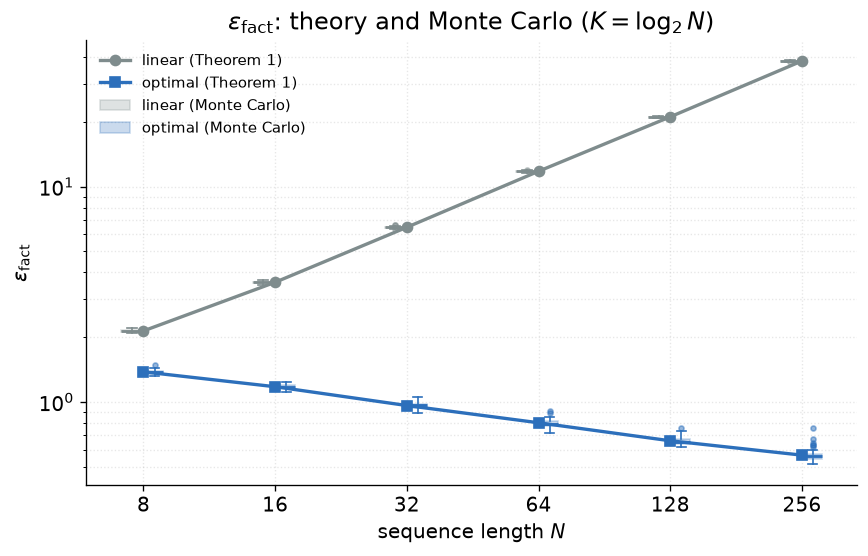

In [8]:
N_values = NS.astype(float)
'''
positions_lin = 0.94 * N_values
positions_opt = 1.06 * N_values
box_widths = 0.10 * N_values
'''

positions_lin = 0.94 *N_values
positions_opt = 1.06 * N_values
box_widths = 0.10 * N_values

fig, ax = plt.subplots(figsize=(7.4, 4.8))

line_lin, = ax.plot(
    N_values, eps_lin_theory,
    color=C_LIN, marker="o",
    label="linear (Theorem 1)",
)
line_opt, = ax.plot(
    N_values, eps_opt_theory,
    color=C_OPT, marker="s",
    label="optimal (Theorem 1)",
)

ax.boxplot(
    eps_lin_mc,
    positions=positions_lin,
    widths=box_widths,
    patch_artist=True,
    manage_ticks=False,
    boxprops={"facecolor": C_LIN, "edgecolor": C_LIN, "alpha": 0.25},
    medianprops={"color": C_LIN, "linewidth": 1.7},
    whiskerprops={"color": C_LIN},
    capprops={"color": C_LIN},
    flierprops={"marker": ".", "markerfacecolor": C_LIN,
                "markeredgecolor": C_LIN, "alpha": 0.5},
)

ax.boxplot(
    eps_opt_mc,
    positions=positions_opt,
    widths=box_widths,
    patch_artist=True,
    manage_ticks=False,
    boxprops={"facecolor": C_OPT, "edgecolor": C_OPT, "alpha": 0.25},
    medianprops={"color": C_OPT, "linewidth": 1.7},
    whiskerprops={"color": C_OPT},
    capprops={"color": C_OPT},
    flierprops={"marker": ".", "markerfacecolor": C_OPT,
                "markeredgecolor": C_OPT, "alpha": 0.5},
)

ax.set_title(
    r"$\varepsilon_{\rm fact}$: theory and Monte Carlo "
    r"($K=\log_2 N$)"
)
ax.set_xlabel(r"sequence length $N$")
ax.set_ylabel(r"$\varepsilon_{\rm fact}$")
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xticks(N_values)
ax.set_xticklabels([str(N) for N in NS])

legend_handles = [
    line_lin,
    line_opt,
    Patch(facecolor=C_LIN, edgecolor=C_LIN, alpha=0.25,
          label="linear (Monte Carlo)"),
    Patch(facecolor=C_OPT, edgecolor=C_OPT, alpha=0.25,
          label="optimal (Monte Carlo)"),
]
ax.legend(handles=legend_handles, frameon=False, fontsize=9)
ax.grid(True, which="both", ls=":", alpha=0.3)

fig.tight_layout()
# fig.savefig("figure3_errors_with_mc_boxplots.png", bbox_inches="tight", dpi=180)
# fig.savefig("figure3_errors_with_mc_boxplots.pdf", bbox_inches="tight")
plt.show()


### Figure 4: improvement ratio

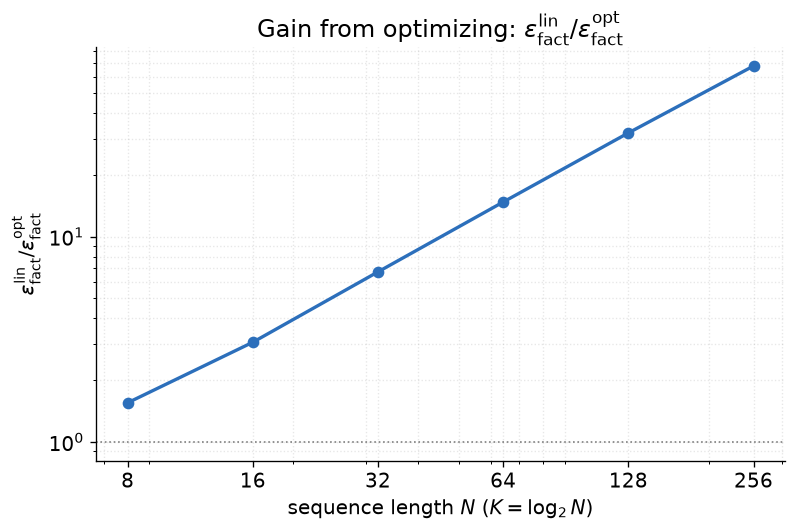

In [9]:
ratio = eps_lin_theory / eps_opt_theory

fig, ax = plt.subplots(figsize=(6.8, 4.6))
ax.loglog(N_values, ratio, color=C_OPT, marker="o", ms=6)
ax.axhline(1.0, color="grey", ls=":", lw=1)

ax.set_title(
    r"Gain from optimizing: "
    r"$\varepsilon_{\rm fact}^{\rm lin}/"
    r"\varepsilon_{\rm fact}^{\rm opt}$"
)
ax.set_xlabel(r"sequence length $N$ ($K=\log_2 N$)")
ax.set_ylabel(
    r"$\varepsilon_{\rm fact}^{\rm lin}/"
    r"\varepsilon_{\rm fact}^{\rm opt}$"
)
ax.set_xticks(N_values)
ax.set_xticklabels([str(N) for N in NS])
ax.grid(True, which="both", ls=":", alpha=0.3)

fig.tight_layout()
# fig.savefig("figure4_error_ratio.png", bbox_inches="tight", dpi=180)
# fig.savefig("figure4_error_ratio.pdf", bbox_inches="tight")
plt.show()


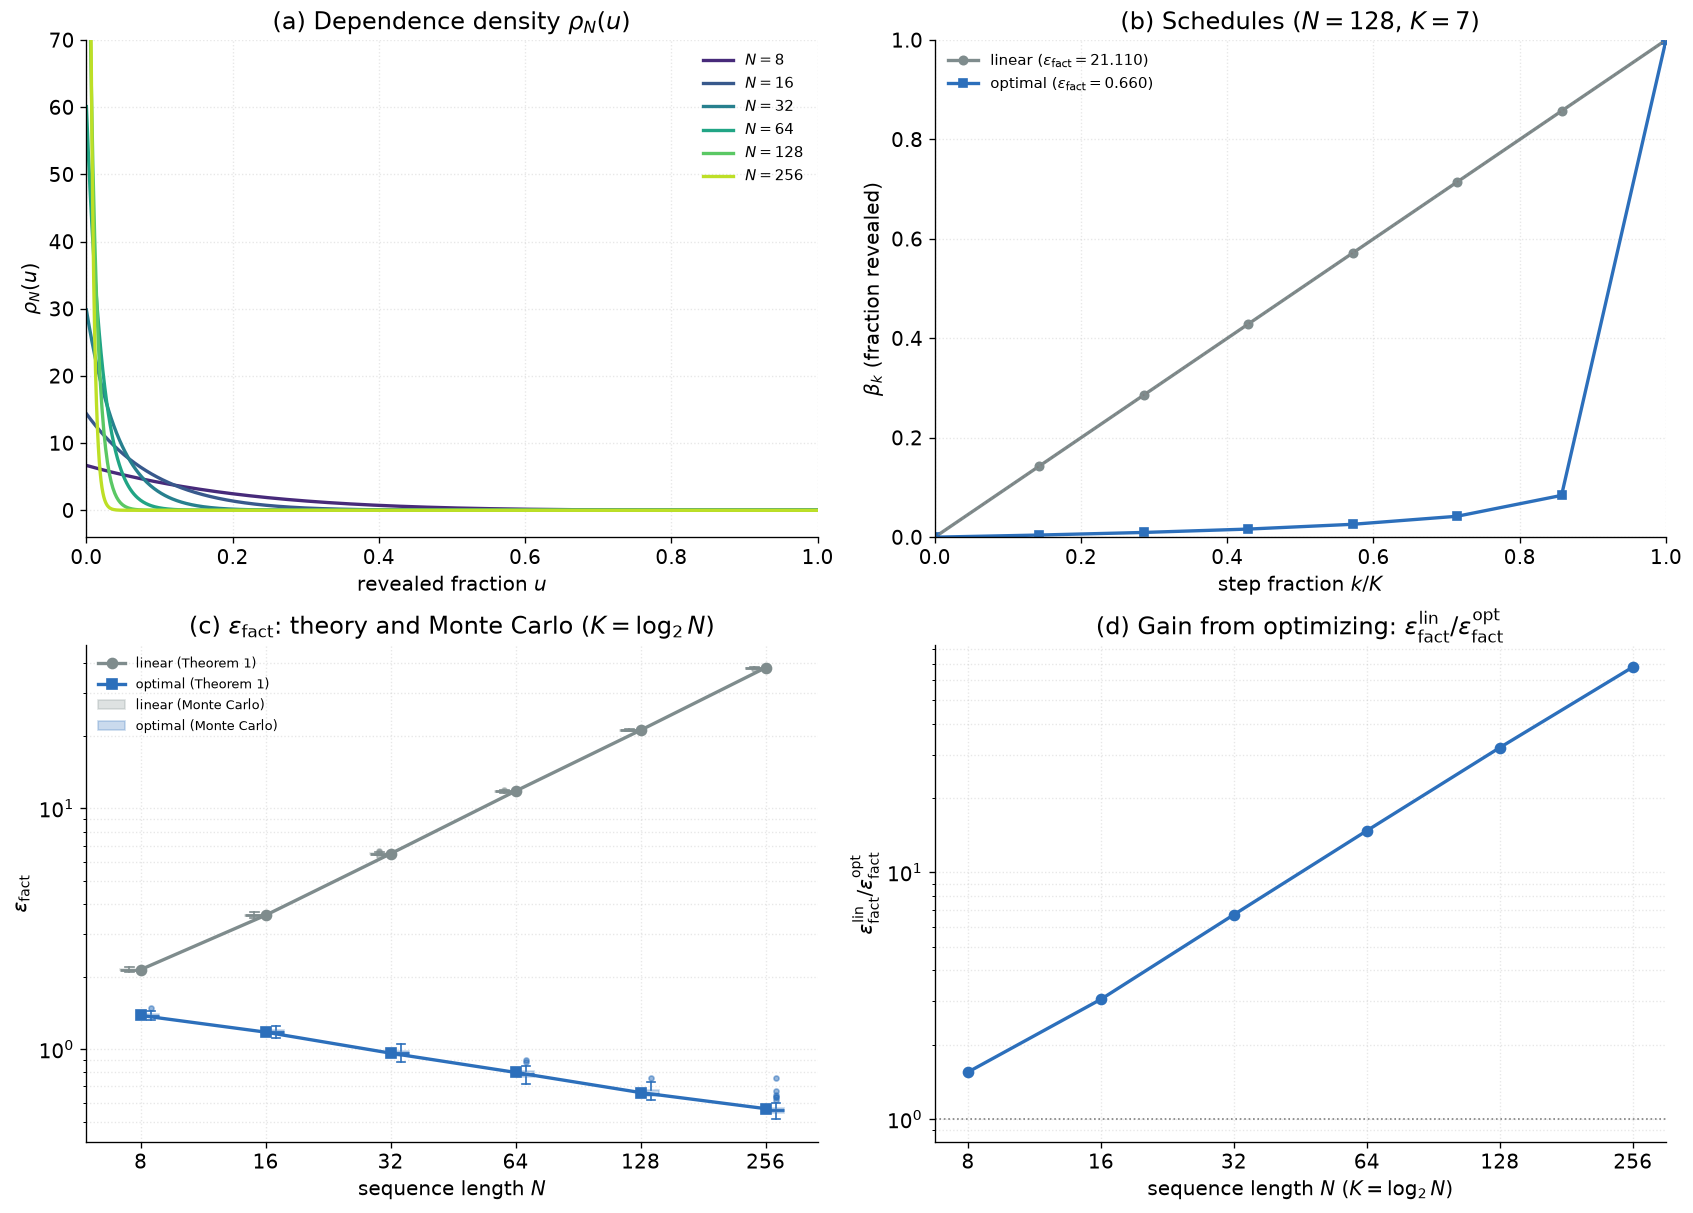

In [ ]:
# ============================================================
# Combine the four figures into one 2 x 2 figure
# ============================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 10),
    constrained_layout=True,
)

# ------------------------------------------------------------
# (a) Dependence profiles for different N
# ------------------------------------------------------------

ax = axes[0, 0]

u = np.linspace(1e-4, 1 - 1e-4, 800)
colors = plt.cm.viridis(
    np.linspace(0.12, 0.90, len(NS_RHO))
)

for N, color in zip(NS_RHO, colors):
    ax.plot(
        u,
        dependence_density(profiles[N], u),
        color=color,
        label=rf"$N={N}$",
    )

ax.set_title(r"(a) Dependence density $\rho_N(u)$")
ax.set_xlabel(r"revealed fraction $u$")
ax.set_ylabel(r"$\rho_N(u)$")
ax.set_xlim(0, 1)
ax.set_ylim(-4, 70)
ax.legend(frameon=False, fontsize=9)
ax.grid(True, ls=":", alpha=0.3)


# ------------------------------------------------------------
# (b) Linear and optimal schedules for N = 128
# ------------------------------------------------------------

ax = axes[0, 1]

ax.plot(
    t,
    beta_lin_fixed,
    color=C_LIN,
    marker="o",
    markersize=5,
    label=(
        rf"linear "
        rf"($\varepsilon_{{\rm fact}}={eps_lin_fixed:.3f}$)"
    ),
)

ax.plot(
    t,
    beta_opt_fixed,
    color=C_OPT,
    marker="s",
    markersize=5,
    label=(
        rf"optimal "
        rf"($\varepsilon_{{\rm fact}}={eps_opt_fixed:.3f}$)"
    ),
)

ax.plot(
    [0, 1],
    [0, 1],
    ":",
    color="grey",
    linewidth=1,
)

ax.set_title(
    rf"(b) Schedules ($N={N_SCHEDULE}$, $K={K_SCHEDULE}$)"
)
ax.set_xlabel(r"step fraction $k/K$")
ax.set_ylabel(r"$\beta_k$ (fraction revealed)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.grid(True, ls=":", alpha=0.3)


# ------------------------------------------------------------
# (c) Theoretical errors and Monte Carlo boxplots
# ------------------------------------------------------------

ax = axes[1, 0]

N_values = NS.astype(float)

# Slightly separate the two boxplots associated with each N
positions_lin = 0.94 * N_values
positions_opt = 1.06 * N_values
box_widths = 0.10 * N_values

line_lin, = ax.plot(
    N_values,
    eps_lin_theory,
    color=C_LIN,
    marker="o",
    label="linear (Theorem 1)",
)

line_opt, = ax.plot(
    N_values,
    eps_opt_theory,
    color=C_OPT,
    marker="s",
    label="optimal (Theorem 1)",
)

ax.boxplot(
    eps_lin_mc,
    positions=positions_lin,
    widths=box_widths,
    patch_artist=True,
    manage_ticks=False,
    boxprops={
        "facecolor": C_LIN,
        "edgecolor": C_LIN,
        "alpha": 0.25,
    },
    medianprops={
        "color": C_LIN,
        "linewidth": 1.7,
    },
    whiskerprops={"color": C_LIN},
    capprops={"color": C_LIN},
    flierprops={
        "marker": ".",
        "markerfacecolor": C_LIN,
        "markeredgecolor": C_LIN,
        "alpha": 0.5,
    },
)

ax.boxplot(
    eps_opt_mc,
    positions=positions_opt,
    widths=box_widths,
    patch_artist=True,
    manage_ticks=False,
    boxprops={
        "facecolor": C_OPT,
        "edgecolor": C_OPT,
        "alpha": 0.25,
    },
    medianprops={
        "color": C_OPT,
        "linewidth": 1.7,
    },
    whiskerprops={"color": C_OPT},
    capprops={"color": C_OPT},
    flierprops={
        "marker": ".",
        "markerfacecolor": C_OPT,
        "markeredgecolor": C_OPT,
        "alpha": 0.5,
    },
)

ax.set_title(
    r"(c) $\varepsilon_{\rm fact}$: theory and Monte Carlo "
    r"($K=\log_2N$)"
)
ax.set_xlabel(r"sequence length $N$")
ax.set_ylabel(r"$\varepsilon_{\rm fact}$")

ax.set_xscale("log", base=2)
ax.set_yscale("log")

ax.set_xticks(N_values)
ax.set_xticklabels([str(N) for N in NS])

error_legend = [
    line_lin,
    line_opt,
    Patch(
        facecolor=C_LIN,
        edgecolor=C_LIN,
        alpha=0.25,
        label="linear (Monte Carlo)",
    ),
    Patch(
        facecolor=C_OPT,
        edgecolor=C_OPT,
        alpha=0.25,
        label="optimal (Monte Carlo)",
    ),
]

ax.legend(
    handles=error_legend,
    frameon=False,
    fontsize=8,
)

ax.grid(True, which="both", ls=":", alpha=0.3)


# ------------------------------------------------------------
# (d) Ratio between linear and optimal errors
# ------------------------------------------------------------

ax = axes[1, 1]

ratio = eps_lin_theory / eps_opt_theory

ax.plot(
    N_values,
    ratio,
    color=C_OPT,
    marker="o",
    markersize=6,
)

ax.axhline(
    1.0,
    color="grey",
    linestyle=":",
    linewidth=1,
)

ax.set_title(
    r"(d) Gain from optimizing: "
    r"$\varepsilon_{\rm fact}^{\rm lin}/"
    r"\varepsilon_{\rm fact}^{\rm opt}$"
)

ax.set_xlabel(r"sequence length $N$ ($K=\log_2N$)")
ax.set_ylabel(
    r"$\varepsilon_{\rm fact}^{\rm lin}/"
    r"\varepsilon_{\rm fact}^{\rm opt}$"
)

ax.set_xscale("log", base=2)
ax.set_yscale("log")

ax.set_xticks(N_values)
ax.set_xticklabels([str(N) for N in NS])

ax.grid(True, which="both", ls=":", alpha=0.3)


# ------------------------------------------------------------
# Save combined figure
# ------------------------------------------------------------

# fig.savefig(
#     "mixture_experiment_four_panels.pdf",
#     bbox_inches="tight",
# )

fig.savefig(
    "mixture_experiment_four_panels.png",
    bbox_inches="tight",
    dpi=300,
)

plt.show()